In [ ]:
 import numpy as np
import pandas as pd

from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import seaborn as sns


from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from lightgbm import LGBMClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error as mse
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score



sns.set(font_scale=1.8, palette='Set2')

In [ ]:
test_orig = pd.read_csv('test_apps.csv')
print("Размер исходного test:", test_orig.shape)
print("Уникальных front_id:", test_orig['front_id'].nunique())
print("Дубли front_id:", test_orig['front_id'].duplicated().sum())

Размер исходного test: (36311, 27)
Уникальных front_id: 36311
Дубли front_id: 0


In [ ]:


train = pd.read_csv('train_apps.csv')
test = pd.read_csv('test_apps.csv')

print(train.shape, test.shape)
print(train['target_value'].mean())  # баланс классов

# Проверка пропусков
print(train.isna().mean().sort_values(ascending=False).head(20))

# Проверка: одна заявка = несколько офферов?
print(train.groupby('front_id').size().describe())

(145241, 28) (36311, 27)
0.06090566713255899
overdraft_app_term_max_360           0.962070
loan_rev_max_start_non_fin           0.913206
sum_deb_investment_90                0.886093
loan_rev_min_start_fin               0.858614
days_from_authperson_registration    0.540295
sum_deb_ul_30                        0.423111
app_term_mean_360                    0.384761
db_group_last                        0.384761
sum_deb_ul_90                        0.372560
corp_list                            0.352435
corp_credit_products                 0.352435
p75_time_spent_minutes               0.352435
count_all_corp_dashboard_events      0.352435
fl_adminarea                         0.298194
balance_rur_amt_30_min               0.239781
cnt_deb_ul_ip_30                     0.229777
cnt_deb_loan_90                      0.216592
cnt_cred_loan_90                     0.216592
cnt_deb_ul_ip_90                     0.208653
fl_hdb_bki_total_active_products     0.167776
dtype: float64
count    145241.0
me

/tmp/ipykernel_1148/1103835182.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train, x='target_value', palette='viridis')


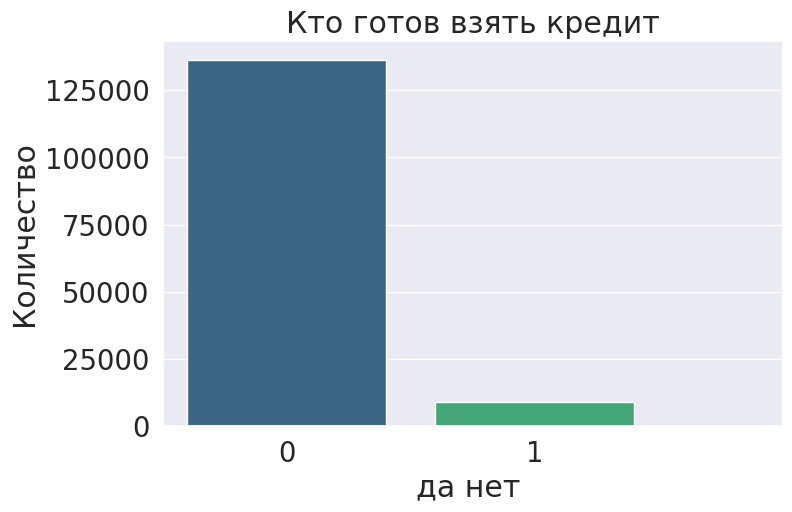

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=train, x='target_value', palette='viridis')
plt.title('Кто готов взять кредит')
plt.xlabel('да нет ')
plt.xticks(ticks=[0, 1, 2])
plt.ylabel('Количество')
plt.show()

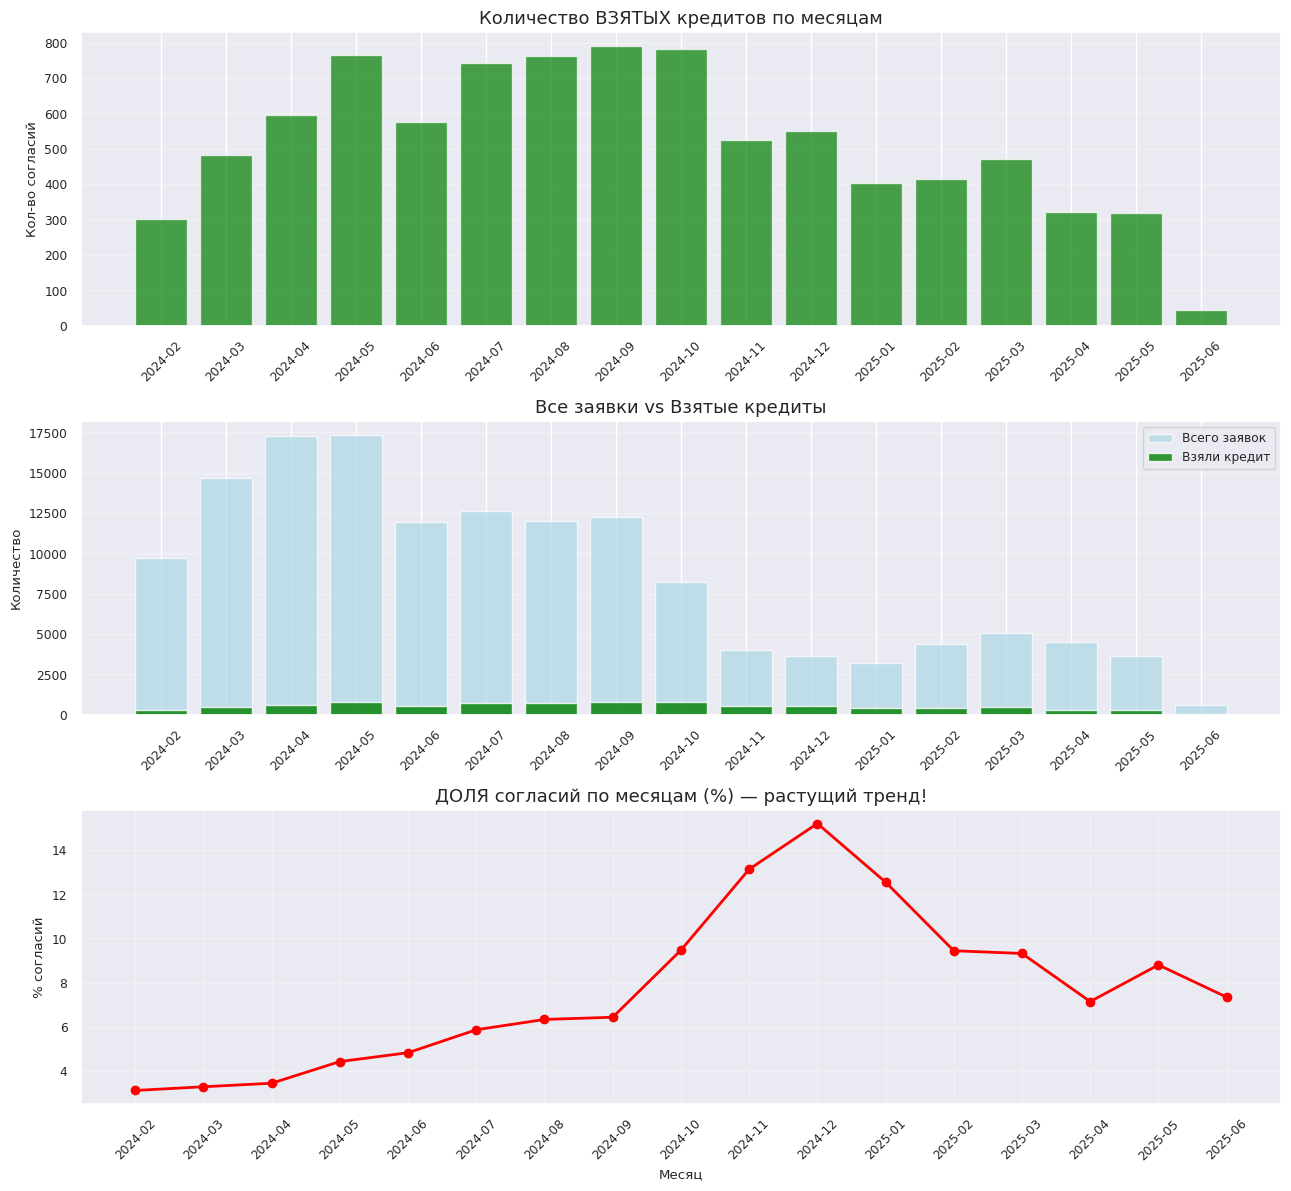

     ym  total  accepted     rate
2024-02   9743       303 0.031099
2024-03  14702       482 0.032785
2024-04  17306       595 0.034381
2024-05  17330       766 0.044201
2024-06  11926       575 0.048214
2024-07  12657       742 0.058624
2024-08  12039       762 0.063294
2024-09  12287       790 0.064296
2024-10   8247       781 0.094701
2024-11   3996       525 0.131381
2024-12   3622       551 0.152126
2025-01   3218       404 0.125544
2025-02   4394       415 0.094447
2025-03   5053       471 0.093212
2025-04   4495       321 0.071413
2025-05   3613       318 0.088015
2025-06    613        45 0.073409


In [ ]:

df = train.copy()
df['date'] = pd.to_datetime(df['decision_day'])
df = df.sort_values('date')

# группируем по месяцам
df['ym'] = df['date'].dt.to_period('M')

monthly = df.groupby('ym').agg(
    total=('target_value', 'size'),
    accepted=('target_value', 'sum'),
    rate=('target_value', 'mean')
).reset_index()
monthly['ym'] = monthly['ym'].astype(str)

fig, axes = plt.subplots(3, 1, figsize=(13, 12))

axes[0].bar(monthly['ym'], monthly['accepted'], color='green', alpha=0.7)
axes[0].set_title('Количество ВЗЯТЫХ кредитов по месяцам', fontsize=13)
axes[0].set_ylabel('Кол-во согласий')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(monthly['ym'], monthly['total'], color='lightblue', alpha=0.7, label='Всего заявок')
axes[1].bar(monthly['ym'], monthly['accepted'], color='green', alpha=0.8, label='Взяли кредит')
axes[1].set_title('Все заявки vs Взятые кредиты', fontsize=13)
axes[1].set_ylabel('Количество')
axes[1].legend()
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(axis='y', alpha=0.3)

axes[2].plot(monthly['ym'], monthly['rate']*100, marker='o', color='red', linewidth=2)
axes[2].set_title('ДОЛЯ согласий по месяцам (%) — растущий тренд!', fontsize=13)
axes[2].set_ylabel('% согласий')
axes[2].set_xlabel('Месяц')
axes[2].tick_params(axis='x', rotation=45)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


print(monthly.to_string(index=False))

Ох йж этот новый код


In [ ]:
import pandas as pd

train = pd.read_csv('train_apps.csv')
test = pd.read_csv('test_apps.csv')

train.head()
train.info()
train.columns.tolist()

X = train.drop('target_value', axis=1)
y = train['target_value']

print(X.shape, y.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145241 entries, 0 to 145240
Data columns (total 28 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   front_id                           145241 non-null  int64  
 1   decision_day                       145241 non-null  object 
 2   loan_amount_last                   145241 non-null  float64
 3   overdraft_limit_min                145241 non-null  float64
 4   overdraft_limit_max                145241 non-null  float64
 5   offered_rate                       145241 non-null  float64
 6   cb_rate                            145241 non-null  float64
 7   corp_credit_products               94053 non-null   float64
 8   sum_deb_ul_90                      91130 non-null   float64
 9   sum_deb_ul_30                      83788 non-null   float64
 10  cnt_deb_loan_90                    113783 non-null  float64
 11  cnt_deb_ul_ip_90                   1149

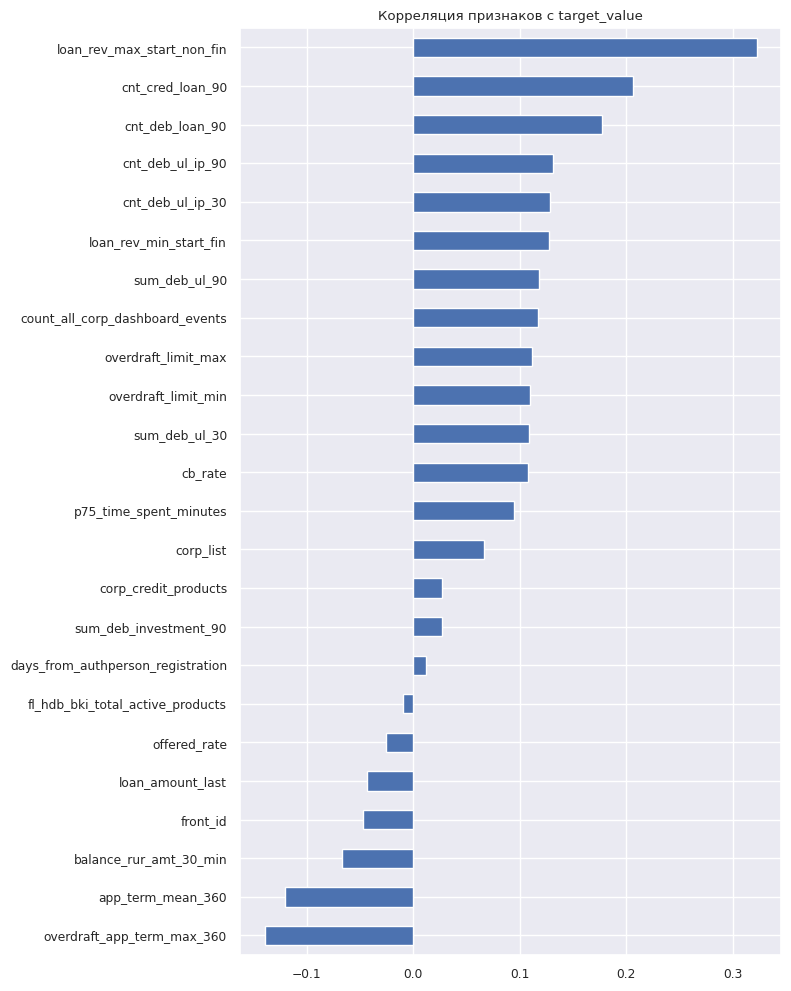

In [ ]:
# Числовые фичи
num = train.select_dtypes(include='number')
corr = num.corr()['target_value'].drop('target_value').sort_values()

plt.figure(figsize=(8, 10))
corr.plot(kind='barh')
plt.title('Корреляция признаков с target_value')
plt.tight_layout()
plt.show()

In [ ]:
print(train.columns.tolist())

['front_id', 'decision_day', 'loan_amount_last', 'overdraft_limit_min', 'overdraft_limit_max', 'offered_rate', 'cb_rate', 'corp_credit_products', 'sum_deb_ul_90', 'sum_deb_ul_30', 'cnt_deb_loan_90', 'cnt_deb_ul_ip_90', 'cnt_deb_ul_ip_30', 'balance_rur_amt_30_min', 'cnt_cred_loan_90', 'loan_rev_max_start_non_fin', 'loan_rev_min_start_fin', 'app_term_mean_360', 'overdraft_app_term_max_360', 'days_from_authperson_registration', 'fl_hdb_bki_total_active_products', 'corp_list', 'count_all_corp_dashboard_events', 'p75_time_spent_minutes', 'sum_deb_investment_90', 'db_group_last', 'fl_adminarea', 'target_value']


Ценовые фичи — насколько выгодно предложение:

rate_spread, rate_ratio — насколько ставка выше ключевой ставки ЦБ. Дороже рынка → клиент реже соглашается.

 Лимиты — щедрое ли предложение:

limit_coverage_max/min — покрывает ли лимит привычный размер кредитов клиента.
limit_gap — насколько широкая «вилка» условий.
loan_vs_maxlimit — банк даёт больше или меньше, чем клиент брал раньше.

 Активность бизнеса — растёт ли клиент:

deb_ul_trend, cnt_ul_ip_trend — ускоряются или замедляются обороты и операции (30 дней против 90). Растущему бизнесу чаще нужны деньги.

loan_pressure — насколько интенсивно клиент обслуживает долги.

 Финансовое состояние:

balance_vs_loan — денежная «подушка» относительно размера кредитов.

balance_vs_turnover — сколько денег лежит без дела относительно оборота (мало → нужен овердрафт).

active_products_ratio — насколько клиент вовлечён в банковские продукты.

 Поведение и лояльность:

digital_engagement — активность в приложении (клики × время). Активные в онлайне чаще принимают предложения.

tenure_years — сколько лет клиент с банком. Старые клиенты лояльнее.
 Логарифмы (log_*) — сжимают огромный разброс денежных сумм (от малого бизнеса до корпораций), чтобы модель не сбивалась на гигантах.

In [ ]:
import numpy as np

def make_features(df):
    df = df.copy()
    eps = 1e-6

    df['rate_spread'] = df['offered_rate'] - df['cb_rate']
    df['rate_ratio']  = df['offered_rate'] / (df['cb_rate'] + eps)

    df['limit_coverage_max'] = df['overdraft_limit_max'] / (df['loan_amount_last'] + eps)
    df['limit_coverage_min'] = df['overdraft_limit_min'] / (df['loan_amount_last'] + eps)
    df['limit_gap']          = df['overdraft_limit_max'] - df['overdraft_limit_min']
    df['loan_vs_maxlimit']   = df['loan_amount_last'] - df['overdraft_limit_max']

    df['deb_ul_trend']    = df['sum_deb_ul_30'] / (df['sum_deb_ul_90'] + eps)
    df['cnt_ul_ip_trend'] = df['cnt_deb_ul_ip_30'] / (df['cnt_deb_ul_ip_90'] + eps)

    df['loan_pressure']         = df['cnt_deb_loan_90'] / (df['cnt_cred_loan_90'] + eps)
    df['active_products_ratio'] = df['fl_hdb_bki_total_active_products'] / (df['corp_credit_products'] + eps)

    df['balance_vs_loan']     = df['balance_rur_amt_30_min'] / (df['loan_amount_last'] + eps)
    df['balance_vs_turnover'] = df['balance_rur_amt_30_min'] / (df['sum_deb_ul_30'] + eps)

    df['digital_engagement'] = df['count_all_corp_dashboard_events'] * df['p75_time_spent_minutes']

    df['tenure_years'] = df['days_from_authperson_registration'] / 365

    # --- Логарифмы денежных фич ---
    for col in ['loan_amount_last', 'overdraft_limit_max', 'sum_deb_ul_90',
                'sum_deb_ul_30', 'balance_rur_amt_30_min', 'sum_deb_investment_90']:
        df['log_' + col] = np.log1p(df[col].clip(lower=0))  \

    return df

train = make_features(train)
test  = make_features(test)

print(" Готово. Всего колонок в train:", train.shape[1])

 Готово. Всего колонок в train: 48


In [ ]:
def add_group_features(df):
    df = df.copy()
    g = df.groupby('front_id')

    df['rate_rank_in_app'] = g['offered_rate'].rank()
    df['rate_min_in_app'] = g['offered_rate'].transform('min')
    df['rate_diff_from_best'] = df['offered_rate'] - df['rate_min_in_app']
    # Ранг лимита внутри заявки
    df['limit_rank_in_app'] = g['overdraft_limit_max'].rank(ascending=False)
    df['limit_max_in_app'] = g['overdraft_limit_max'].transform('max')

    df['n_offers_in_app'] = g['front_id'].transform('count')
    return df

train = add_group_features(train)
test = add_group_features(test)

In [ ]:
cat_features = ['db_group_last', 'fl_adminarea']  # категориальные
drop_cols = ['front_id', 'target_value']
features = [c for c in train.columns if c not in drop_cols]

X = train[features]
y = train['target_value']
groups = train['front_id']

# приводим категории к строкам для CatBoost
for c in cat_features:
    X[c] = X[c].astype(str)
    test[c] = test[c].astype(str)

/tmp/ipykernel_1148/3421269216.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[c] = X[c].astype(str)
/tmp/ipykernel_1148/3421269216.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[c] = X[c].astype(str)


In [ ]:
import pandas as pd
import numpy as np

# 1. Превращаем дату в число (сколько дней прошло) + компоненты
def process_date(df):
    df = df.copy()
    df['decision_day'] = pd.to_datetime(df['decision_day'])
    # компоненты даты — полезные фичи
    df['dow']   = df['decision_day'].dt.dayofweek       # день недели (0-6)
    df['month'] = df['decision_day'].dt.month           # месяц
    df['day']   = df['decision_day'].dt.day             # число месяца
    # дата как число (дней от старта) — чтобы уловить тренд во времени
    df['date_ordinal'] = (df['decision_day'] - pd.Timestamp('2024-01-01')).dt.days
    return df

train = process_date(train)
test  = process_date(test)

In [ ]:
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score

cat_features = ['db_group_last', 'fl_adminarea']

drop_cols = ['front_id', 'target_value', 'decision_day']
features = [c for c in train.columns if c not in drop_cols]

X = train[features].copy()
y = train['target_value']
groups = train['front_id']

for c in cat_features:
    X[c] = X[c].astype(str)
    test[c] = test[c].astype(str)

print(X.dtypes[X.dtypes == 'object'])

db_group_last    object
fl_adminarea     object
dtype: object


In [ ]:
from catboost import CatBoostClassifier, Pool

gkf = GroupKFold(n_splits=5)
oof = np.zeros(len(train))
test_pred = np.zeros(len(test))
scores = []

for fold, (tr_idx, val_idx) in enumerate(gkf.split(X, y, groups)):
    X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]

    model = CatBoostClassifier(
        iterations=3000,
        learning_rate=0.03,
        depth=6,
        l2_leaf_reg=5,
        eval_metric='AUC',
        cat_features=cat_features,
        random_seed=42,
        early_stopping_rounds=200,
        verbose=200
    )
    model.fit(X_tr, y_tr, eval_set=(X_val, y_val))

    oof[val_idx] = model.predict_proba(X_val)[:, 1]
    test_pred += model.predict_proba(test[features])[:, 1] / gkf.n_splits
    score = roc_auc_score(y_val, oof[val_idx])
    scores.append(score)
    print(f'Fold {fold} AUC: {score:.5f}')

print(f'\nOOF AUC: {roc_auc_score(y, oof):.5f}')
print(f'Mean fold AUC: {np.mean(scores):.5f} +/- {np.std(scores):.5f}')

0:	test: 0.7089114	best: 0.7089114 (0)	total: 198ms	remaining: 9m 53s
200:	test: 0.8408955	best: 0.8408955 (200)	total: 20.2s	remaining: 4m 40s
400:	test: 0.8453927	best: 0.8454204 (398)	total: 39.8s	remaining: 4m 17s
600:	test: 0.8467981	best: 0.8468109 (598)	total: 58.8s	remaining: 3m 54s
800:	test: 0.8474318	best: 0.8474854 (773)	total: 1m 18s	remaining: 3m 34s
1000:	test: 0.8476872	best: 0.8477425 (957)	total: 1m 37s	remaining: 3m 15s
1200:	test: 0.8474476	best: 0.8478159 (1032)	total: 1m 56s	remaining: 2m 54s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.8478158752
bestIteration = 1032

Shrink model to first 1033 iterations.
Fold 0 AUC: 0.84782
0:	test: 0.6783377	best: 0.6783377 (0)	total: 84.1ms	remaining: 4m 12s
200:	test: 0.8140140	best: 0.8140140 (200)	total: 19.9s	remaining: 4m 37s
400:	test: 0.8185303	best: 0.8185303 (400)	total: 38.9s	remaining: 4m 12s
600:	test: 0.8208236	best: 0.8208236 (600)	total: 58.4s	remaining: 3m 53s
800:	test: 0.8220310	best:

In [ ]:
submission = pd.DataFrame({
    'front_id': test['front_id'],
    'target_value': test_pred
})
submission.to_csv("submission.csv", index=False)
print(" submission.csv сохранён!")
print(submission.head())

Слишком высокоб, дата лик наверно
, тестовые данные наверняка в будущем нада учесть

In [ ]:
order = train.sort_values('decision_day').index

X_sorted = X.loc[order].reset_index(drop=True)
y_sorted = y.loc[order].reset_index(drop=True)

n = len(X_sorted)

In [ ]:

order = train.sort_values('decision_day').index
X_sorted = X.loc[order].reset_index(drop=True)
y_sorted = y.loc[order].reset_index(drop=True)

n = len(X_sorted)
oof = np.zeros(n)
test_pred = np.zeros(len(test))
scores = []

n_splits = 5

val_starts = np.linspace(int(n*0.5), n, n_splits+1).astype(int)

for fold in range(n_splits):
    val_start = val_starts[fold]
    val_end   = val_starts[fold+1]

    tr_idx  = np.arange(0, val_start)          # всё ДО валид-блока (прошлое)
    val_idx = np.arange(val_start, val_end)    # валид-блок (будущее)

    X_tr, X_val = X_sorted.iloc[tr_idx], X_sorted.iloc[val_idx]
    y_tr, y_val = y_sorted.iloc[tr_idx], y_sorted.iloc[val_idx]
    X_tr = X_tr.drop(columns=['date_ordinal'], errors='ignore')
    X_val = X_val.drop(columns=['date_ordinal'], errors='ignore')

    model = CatBoostClassifier(
        iterations=3000,
        learning_rate=0.03,
        depth=6,
        l2_leaf_reg=5,
        eval_metric='AUC',
        cat_features=cat_features,
        random_seed=42,
        early_stopping_rounds=200,
        verbose=0
    )
    model.fit(X_tr, y_tr, eval_set=(X_val, y_val))

    oof[val_idx] = model.predict_proba(X_val)[:, 1]
    test_pred += model.predict_proba(test[features])[:, 1] / n_splits

    score = roc_auc_score(y_val, oof[val_idx])
    scores.append(score)
    print(f'Fold {fold}: train={len(tr_idx):6d}, val={len(val_idx):5d}, '
          f'val_доля1={y_val.mean():.3f}, AUC={score:.5f}')

val_mask = np.arange(n) >= val_starts[0]
print(f'\nOOF AUC (валид. часть): {roc_auc_score(y_sorted[val_mask], oof[val_mask]):.5f}')
print(f'Mean fold AUC: {np.mean(scores):.5f} +/- {np.std(scores):.5f}')

Fold 0: train= 72620, val=14524, val_доля1=0.060, AUC=0.82855
Fold 1: train= 87144, val=14524, val_доля1=0.063, AUC=0.79308
Fold 2: train=101668, val=14524, val_доля1=0.082, AUC=0.78746
Fold 3: train=116192, val=14524, val_доля1=0.125, AUC=0.77674
Fold 4: train=130716, val=14525, val_доля1=0.085, AUC=0.75004

OOF AUC (валид. часть): 0.78506
Mean fold AUC: 0.78717 +/- 0.02544


In [ ]:
import pandas as pd

sub = pd.read_csv('sample_submission.csv')
print("Колонки:", sub.columns.tolist())
print(sub.head())
print("Размер sample_submission:", sub.shape)
print("Размер test:", test.shape)

Колонки: ['front_id', 'target_value']
   front_id  target_value
0    238459           0.5
1    151533           0.5
2    195027           0.5
3    195034           0.5
4    129620           0.5
Размер sample_submission: (45032, 2)
Размер test: (36311, 57)


Пробовала стекинг с light boost, но хороших результатов не дал